# Transformation and feature engineering

Reconstructed from the evaluation notebook; its original version is retained in `archive/pre_restructure/evaluation.ipynb`. The EDA notebook is unchanged.

Run this notebook first. It exports **data/processed/** for later modeling: five stratified 70/15/15 splits, each with RFE-CART and direct CART top-20 selection. For each seed, imputation and feature selection are fitted on training rows; continuous measurements receive Yeo-Johnson followed by standardization and categories receive one-hot encoding. A separate transformer fitted on development rows prepares the 85% refit and untouched 15% test sets.

**Labels:** source 0 means present, source 1 means absent. Exported `gallstones_present` uses 1 = present and 0 = absent. Do not include `source_row` or the target as a predictor.

The root `transformed_dataset.csv` is a full-data fitted reference export for exploration/final fitting, **not** an evaluation input. Holdout, tuning and leave-one-out use their own training-fitted transformed partitions. LOPO fold exports are generated on demand by its notebook.


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Locate the project when launched from its root or notebooks directory.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "utils.py").is_file() and (p / "data/raw/dataset_gallstone").is_file())
sys.path.insert(0, str(ROOT))
from utils import (DEFAULT_SEEDS, DATASET_DIR, REPORT_METRICS, WORKFLOW_MODELS,
                   workflow_data, require_exports, prepare_holdout_exports,
                   load_pickle, continuous_columns, plot_evaluation)
sns.set_theme(style="whitegrid")


## 1. Prepare and export transformed datasets

Defaults are seeds 42, 7, 21, 84 and 123. Twenty means source predictors; one-hot encoding may increase the exported column count. CART may retain zero-importance fields if fewer than 20 have positive importance. Cached exports are reused only when the source signature and split/selection settings match.


In [3]:
SEEDS = list(DEFAULT_SEEDS)
SELECTIONS = ["rfe", "cart"]
TOP_K = 20
manifest = prepare_holdout_exports(SEEDS, SELECTIONS, TOP_K)
X, y = workflow_data()
display(pd.DataFrame({"category": ["Present", "Absent"], "model_target": [1, 0],
                      "count": [int(y.sum()), int((1-y).sum())]}))
split_tables = []
for seed in SEEDS:
    membership = pd.read_csv(DATASET_DIR / "holdout" / f"seed_{seed}" / "split_membership.csv")
    split_tables.append(membership.groupby("split").size().rename(seed))
display(pd.concat(split_tables, axis=1))
display(pd.read_csv(DATASET_DIR / "transformed_dataset.csv").head())


Transformed holdout partitions: seed 42
Transformed holdout partitions: seed 7
Transformed holdout partitions: seed 21
Transformed holdout partitions: seed 84
Transformed holdout partitions: seed 123


,category,model_target,count
0,Present,1,161
1,Absent,0,158


,42,7,21,84,123
split,,,,,
test,48,48,48,48,48
train,223,223,223,223,223
validation,48,48,48,48,48


,source_row,continuous__weight,continuous__tbw,continuous__ecw,continuous__ecf_tbw,continuous__bm,continuous__tfc,continuous__vma_kg,continuous__ldl,continuous__ast,...,categorical__hyperlipidemia_0,categorical__hyperlipidemia_1,categorical__dm_0,categorical__dm_1,categorical__hfa_0,categorical__hfa_1,categorical__hfa_2,categorical__hfa_3,categorical__hfa_4,gallstones_present
0,0,0.812360,1.509427,1.301014,-0.731666,1.661968,-0.519848,2.109376,1.234580,0.249624,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1
1,1,0.909587,0.349673,0.772283,0.864148,0.804322,0.840725,0.511307,-0.444322,-0.838537,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1
2,2,0.713818,0.845828,0.959384,0.189023,0.982705,0.266782,0.805951,-0.018024,-0.041880,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1
3,3,-0.803328,0.138783,-0.013524,-0.436785,0.246074,-1.522747,-0.276648,-1.458144,0.249624,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1
4,4,0.625744,1.337526,0.928239,-1.014786,1.328903,-0.507583,1.581259,0.735652,0.960585,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1


## 2. Feature-selection importance

The charts use the first seed's **training-only** CART selectors. RFE importance belongs to its final reduced CART tree; direct CART importance comes from its full candidate tree. These impurity scores are not causal effects and can favor correlated or high-cardinality variables.


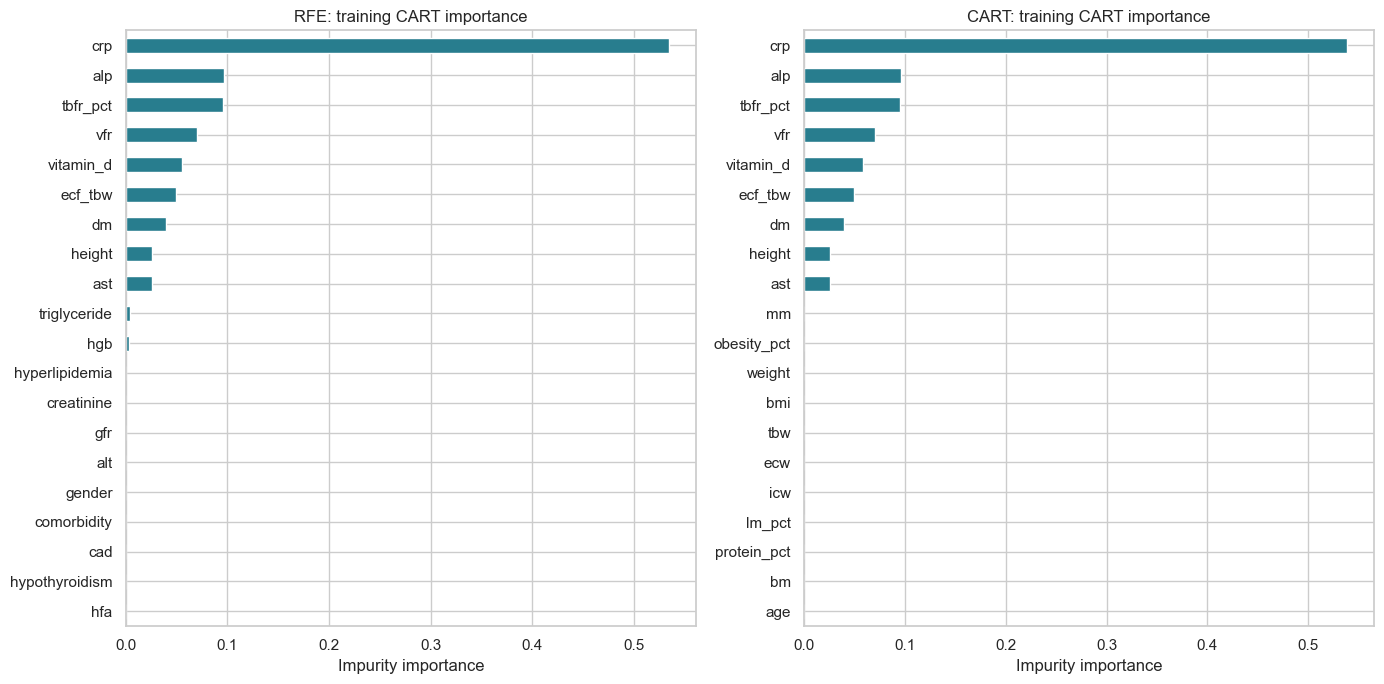

In [4]:
VIS_SEED = SEEDS[0]
VIS_OUTPUT = DATASET_DIR / "visualizations"
VIS_OUTPUT.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, selection in zip(axes, SELECTIONS):
    directory = DATASET_DIR / "holdout" / f"seed_{VIS_SEED}" / selection / "training"
    preparation = load_pickle(directory / "transformer.pkl")
    selector = preparation.named_steps["select"]
    names = preparation.named_steps["impute"].get_feature_names_out()
    if hasattr(selector, "ranking_"):
        names = names[selector.get_support()]
    importance = pd.Series(selector.estimator_.feature_importances_, index=names).nlargest(20).sort_values()
    importance.plot.barh(ax=ax, color="#287D8E")
    ax.set(title=f"{selection.upper()}: training CART importance", xlabel="Impurity importance")
    importance.rename("importance").to_csv(VIS_OUTPUT / f"{selection}_importance.csv")
fig.tight_layout()
fig.savefig(VIS_OUTPUT / "feature_selection_importance.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Yeo-Johnson and standardization visualization

Compare imputed original values, Yeo-Johnson values, and standardized values for selected continuous predictors. The existing training-fitted transformer is applied without refitting. Coded categorical fields are excluded. Standardization changes location and scale but preserves skewness.


,lambda,original_skew,yeo_johnson_skew,standardized_skew,standardized_mean,standardized_std
height,1.301391,-0.053986,-0.017669,-0.017669,-3.176333e-16,1.0
ecf_tbw,3.374701,-0.688216,0.023216,0.023216,4.142177e-16,1.0
tbfr_pct,0.850739,0.091125,-0.025431,-0.025431,-2.628689e-16,1.0
vfr,0.478378,1.017807,0.027236,0.027236,3.345605e-16,1.0
triglyceride,-0.235091,2.989710,-0.001080,-0.001080,2.409632e-15,1.0
ast,-0.907754,6.383039,-0.050331,-0.050331,-4.221835e-16,1.0
alt,-0.413444,7.471389,-0.097690,-0.097690,-1.593145e-17,1.0
alp,0.660685,0.540931,0.079101,0.079101,4.779435e-17,1.0
creatinine,-1.721033,0.652447,0.035357,0.035357,-6.472152e-16,1.0
gfr,2.791296,-1.766692,-0.158434,-0.158434,7.368296e-17,1.0


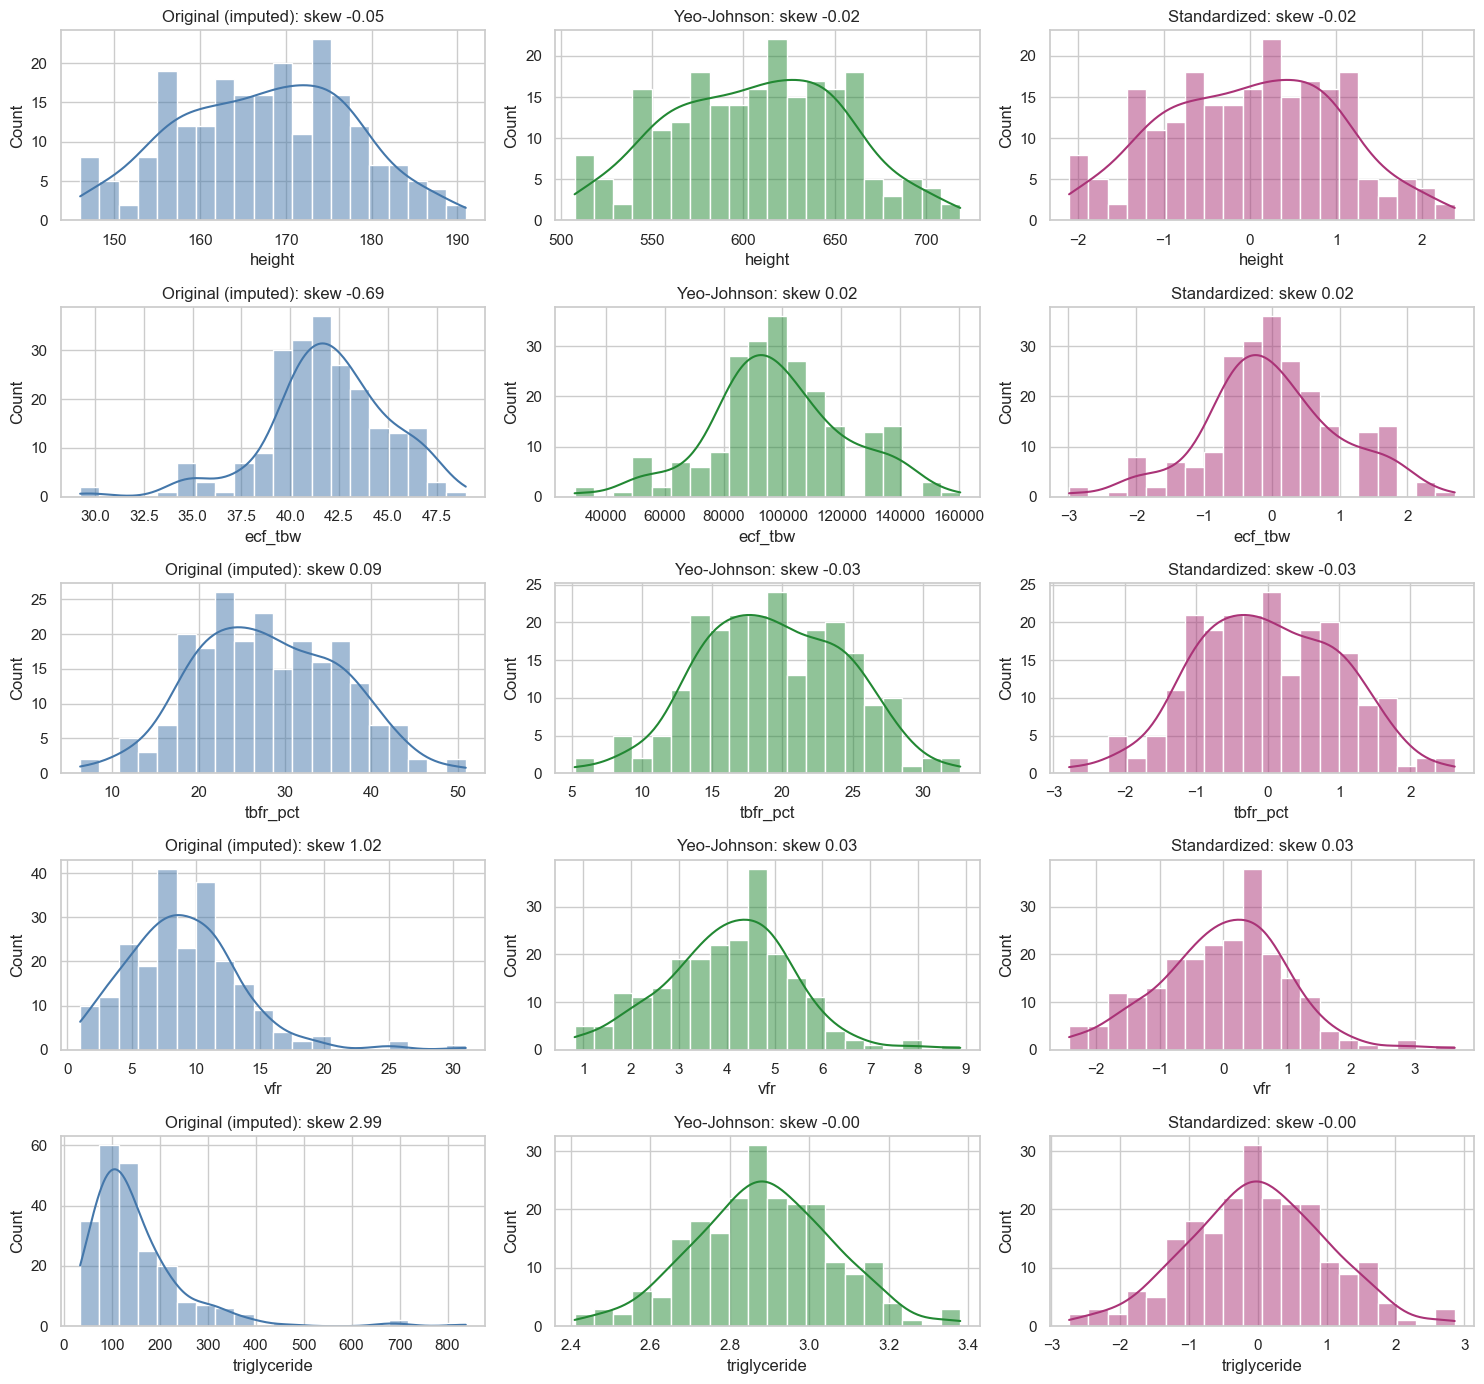

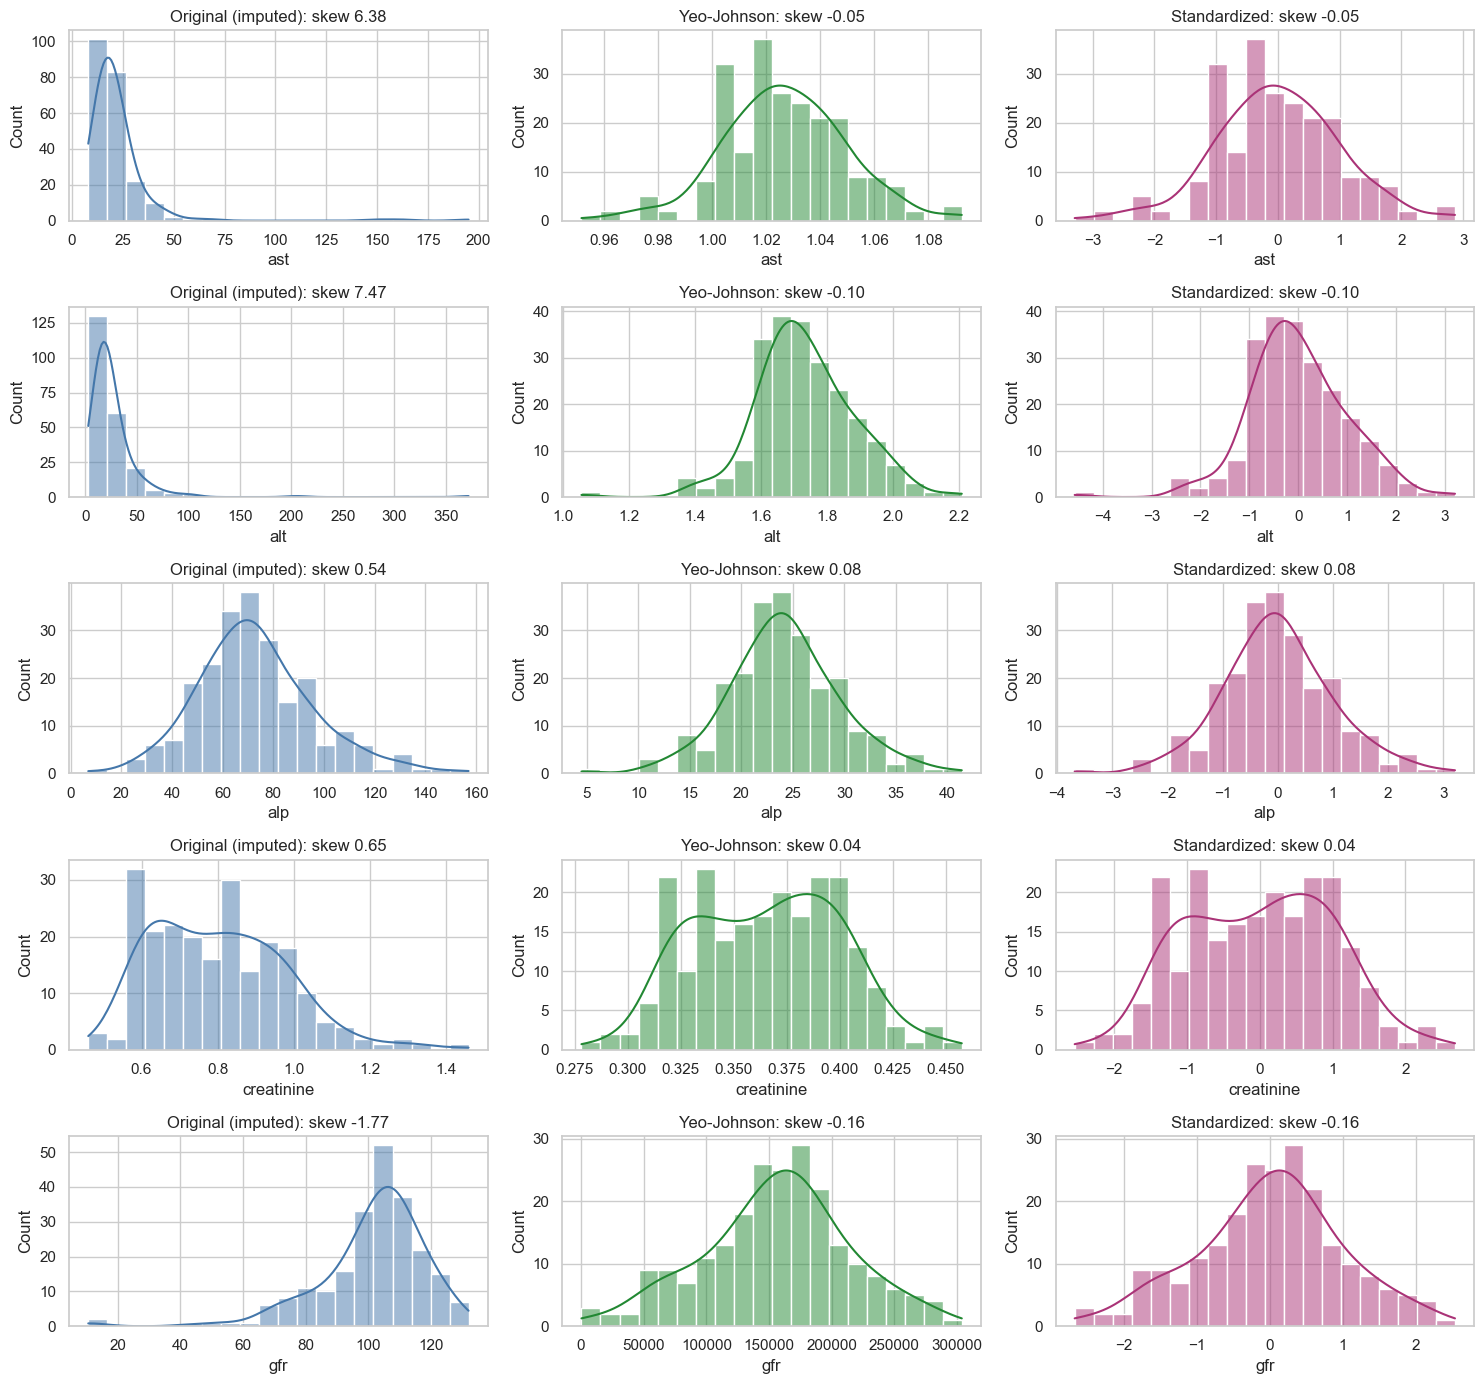

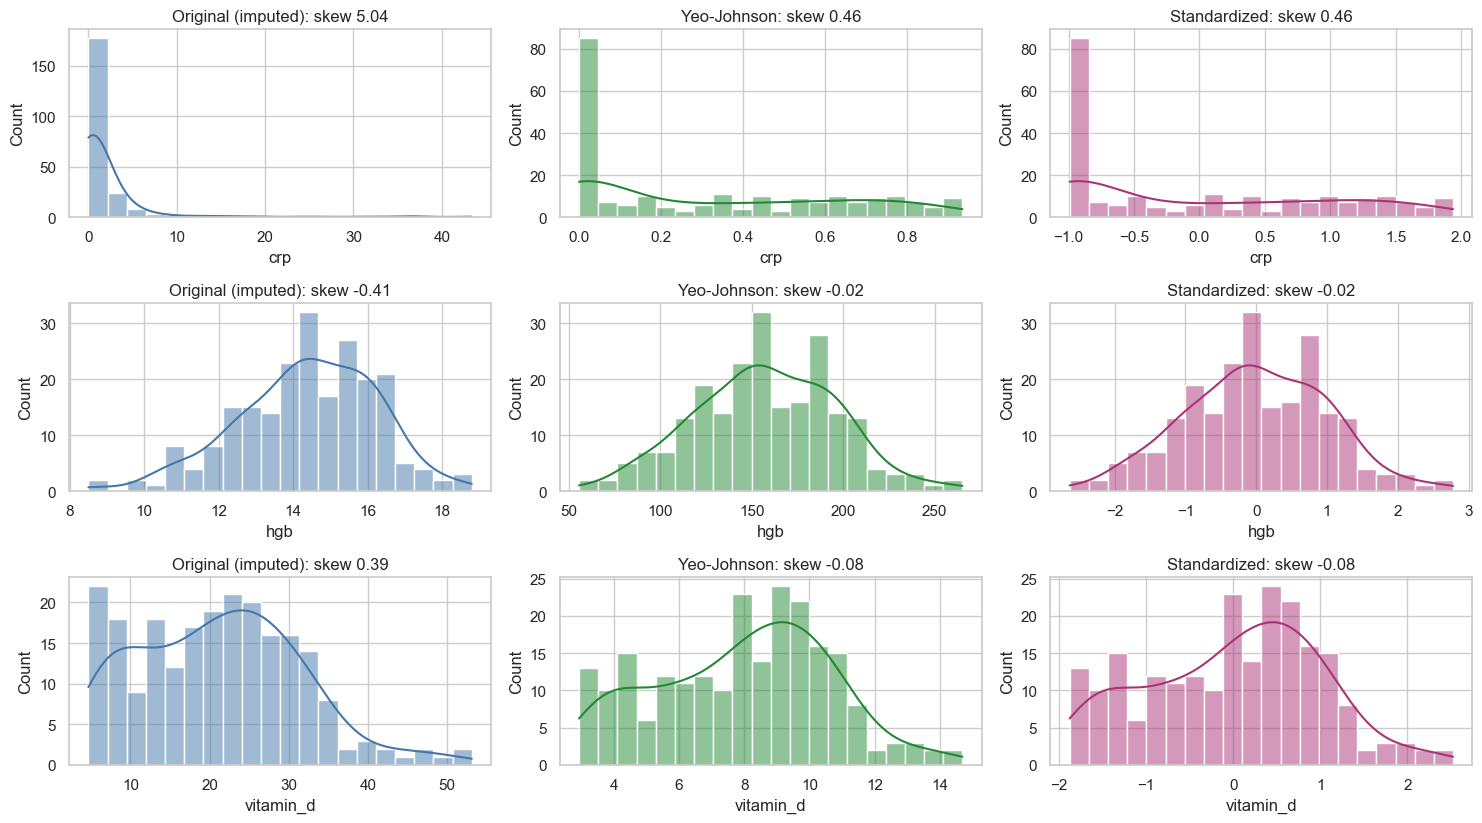

In [5]:
VIS_SELECTION = "rfe"
directory = DATASET_DIR / "holdout" / f"seed_{VIS_SEED}" / VIS_SELECTION / "training"
preparation = load_pickle(directory / "transformer.pkl")
fit_rows = pd.read_csv(directory / "train.csv").source_row
imputed = preparation.named_steps["impute"].transform(X.loc[fit_rows])
selected = preparation.named_steps["select"].transform(imputed)
fields = continuous_columns(selected)
numeric = preparation.named_steps["transform"].named_transformers_["continuous"]
original = selected[fields]
yj = pd.DataFrame(numeric.named_steps["yeo_johnson"].transform(original), columns=fields)
standardized = pd.DataFrame(numeric.named_steps["standardize"].transform(yj.to_numpy()), columns=fields)
statistics = pd.DataFrame({"lambda": numeric.named_steps["yeo_johnson"].lambdas_,
                           "original_skew": original.skew(), "yeo_johnson_skew": yj.skew(),
                           "standardized_skew": standardized.skew(),
                           "standardized_mean": standardized.mean(),
                           "standardized_std": standardized.std(ddof=0)}, index=fields)
display(statistics)
statistics.to_csv(VIS_OUTPUT / "transformation_statistics.csv")
np.testing.assert_allclose(standardized.mean(), 0, atol=1e-8)
np.testing.assert_allclose(yj.skew(), standardized.skew(), atol=1e-8, equal_nan=True)
for start in range(0, len(fields), 5):
    batch = fields[start:start+5]
    fig, axes = plt.subplots(len(batch), 3, figsize=(15, 2.8*len(batch)), squeeze=False)
    for row, field in enumerate(batch):
        for col, (label, values, color) in enumerate([
            ("Original (imputed)", original, "#4477AA"), ("Yeo-Johnson", yj, "#228833"),
            ("Standardized", standardized, "#AA3377")]):
            sns.histplot(values[field], bins=20, kde=values[field].nunique()>1, ax=axes[row,col], color=color)
            axes[row,col].set(title=f"{label}: skew {values[field].skew():.2f}", xlabel=field)
    fig.tight_layout()
    fig.savefig(VIS_OUTPUT / f"transformations_{start//5+1}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 4. Sample CART trees

These examples show the fitted **direct CART selector** and the **final CART estimator inside RFE** for two training splits. They are feature-selection trees, not the final prediction models. The direct CART tree was fitted on all candidate predictors; the RFE tree was fitted on its selected 20.

Only the top three levels are displayed for readability (`TREE_DISPLAY_DEPTH = 2`); truncated branches are marked with ellipses. Change `TREE_SEEDS` or the display depth below to inspect other examples. The saved text files contain the complete trees.

Split thresholds use imputed original measurements or the original category codes, because selection happens **before Yeo-Johnson and standardization**. The class labels use the recoded modeling target: **Absent = 0, Present = 1**. Follow the left branch when a split condition is true and the right branch when it is false. Gini measures class impurity, samples gives the training-row count, and value shows the node's class distribution in [Absent, Present] order. These are descriptive fitted rules, not causal or clinical decision rules.


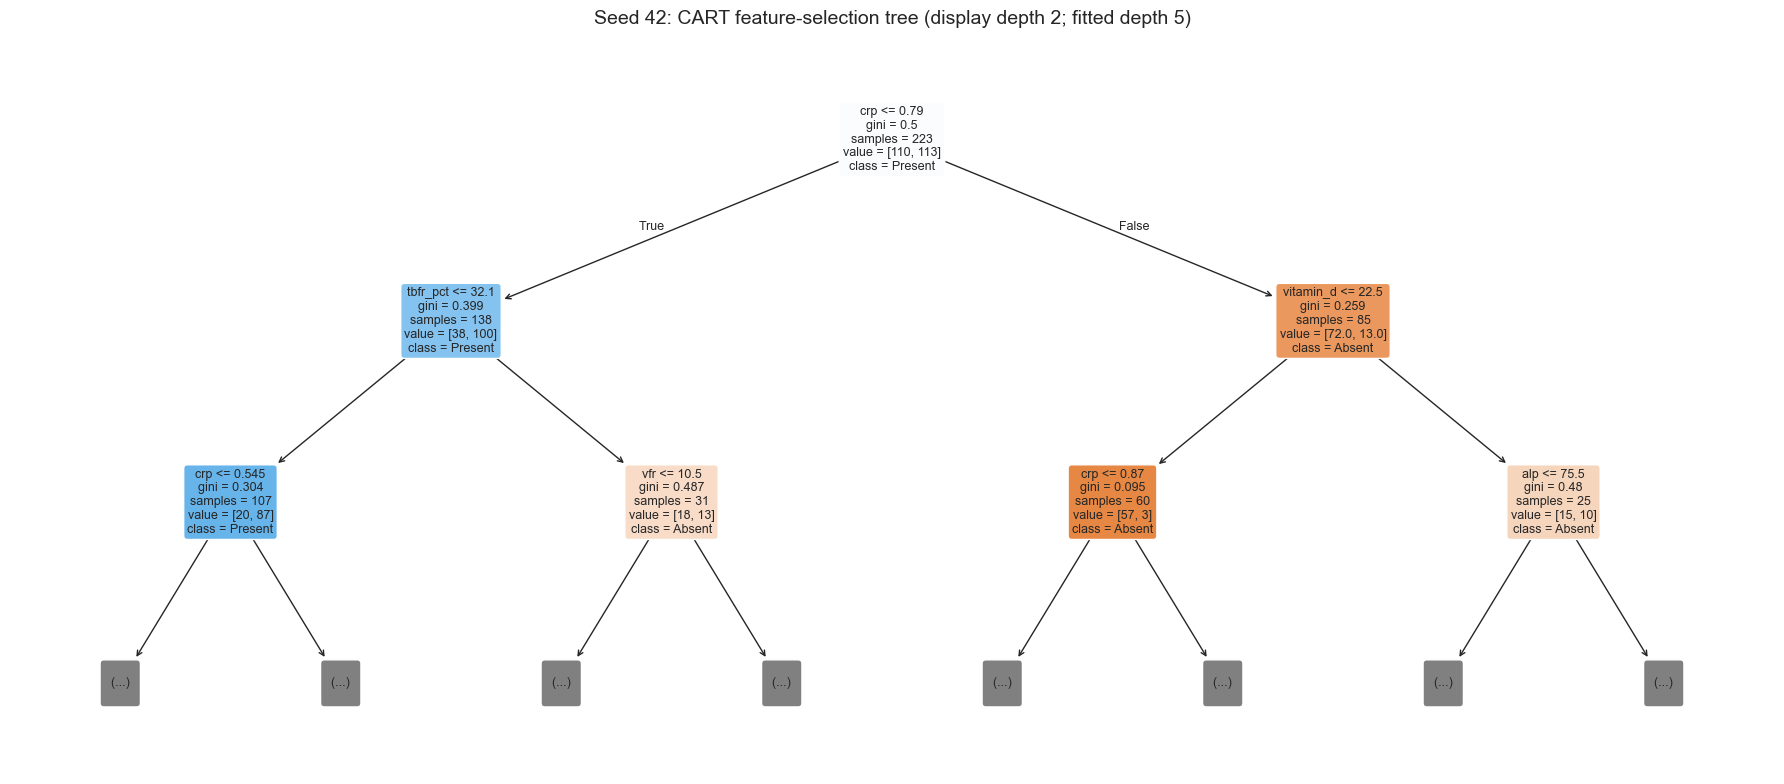

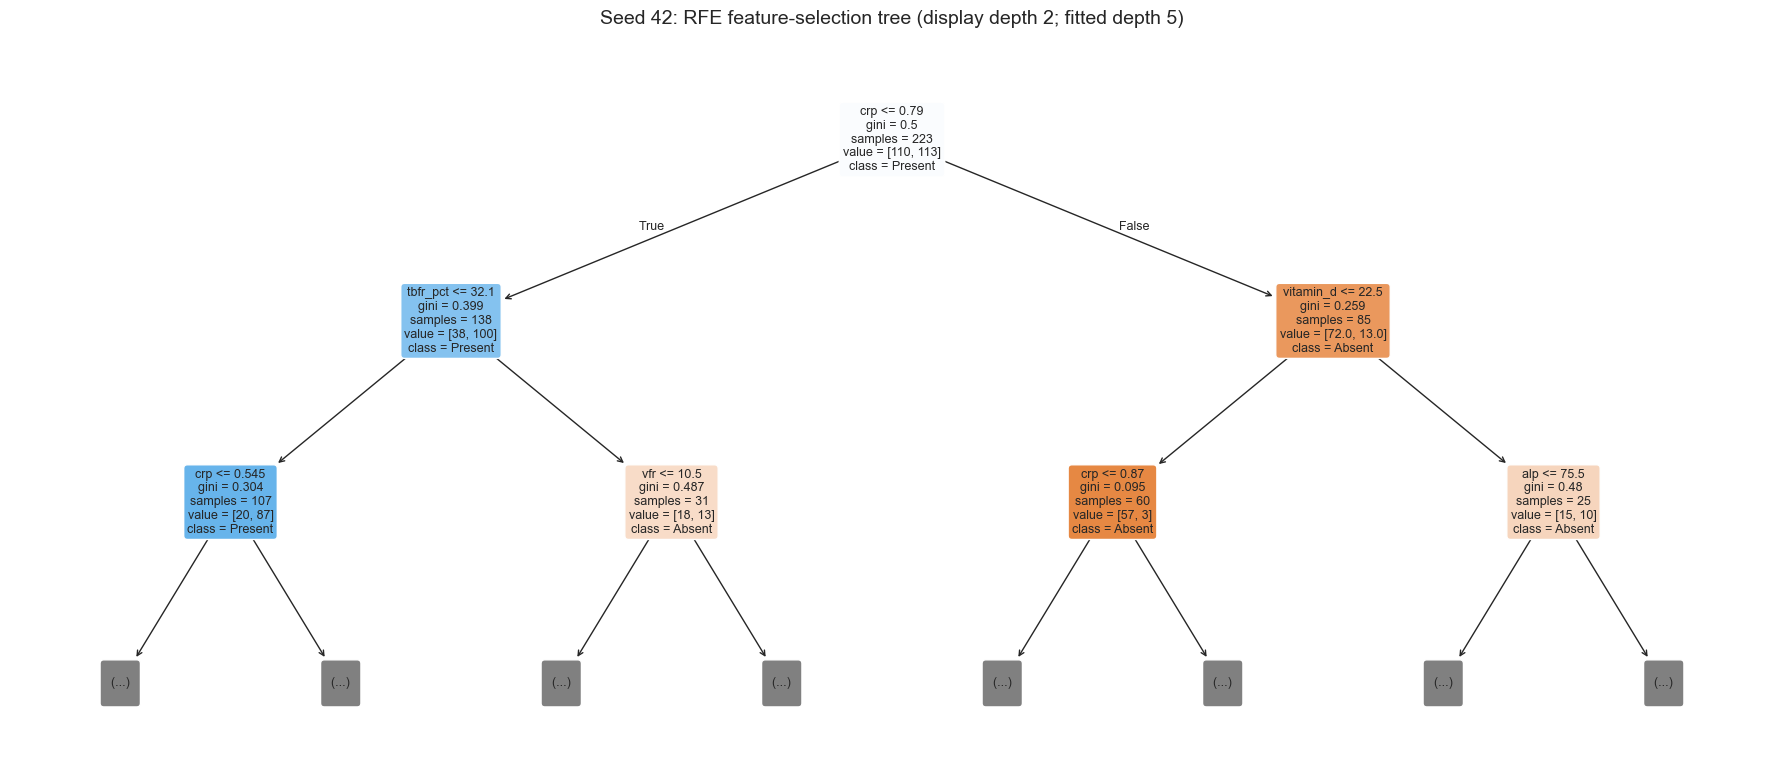

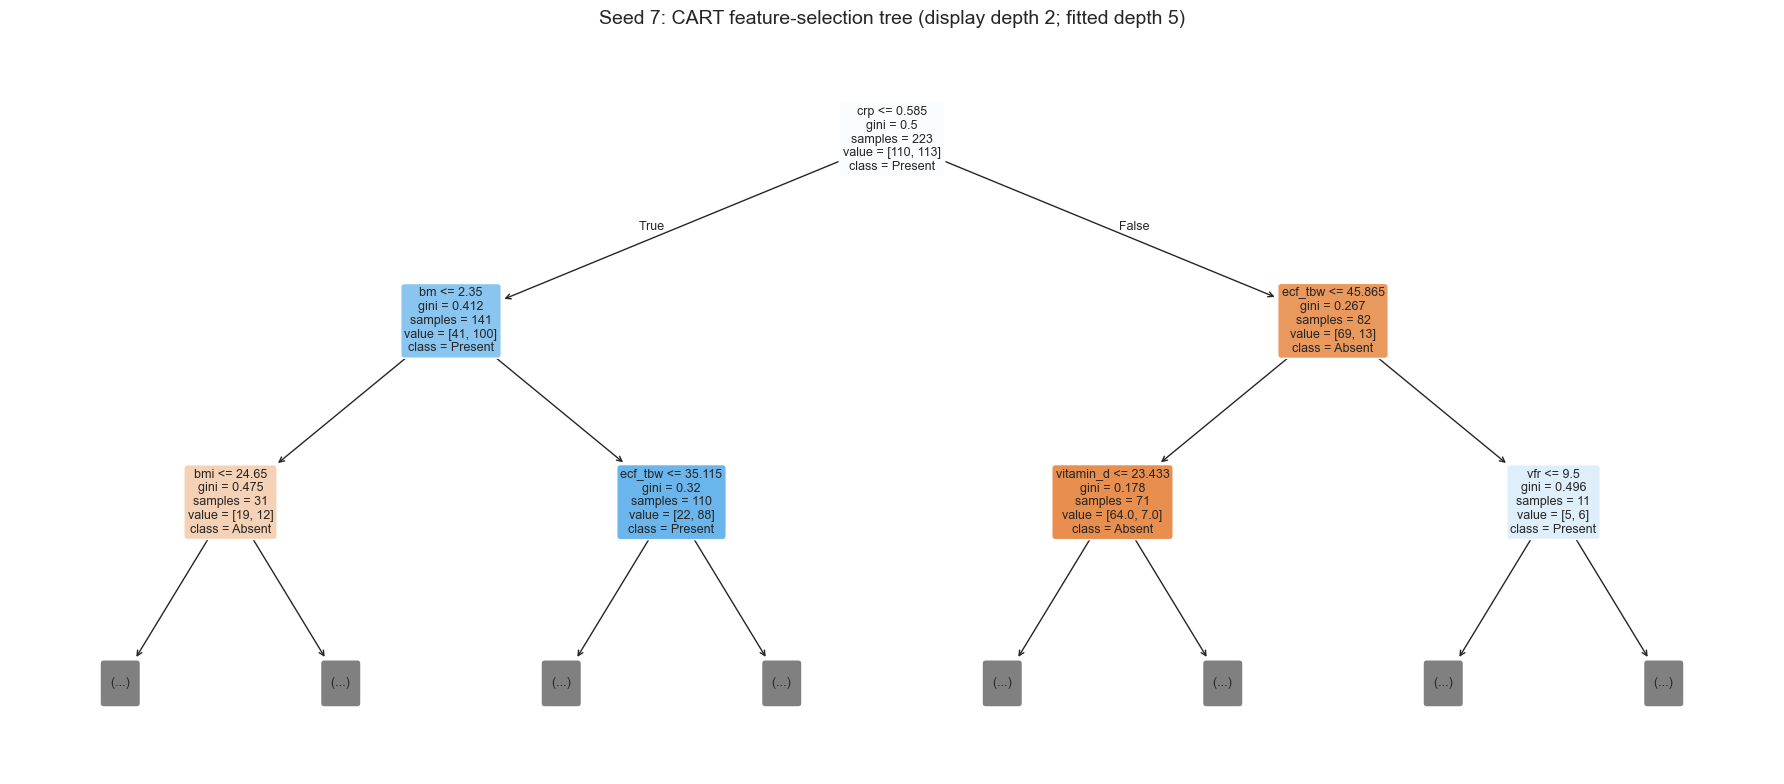

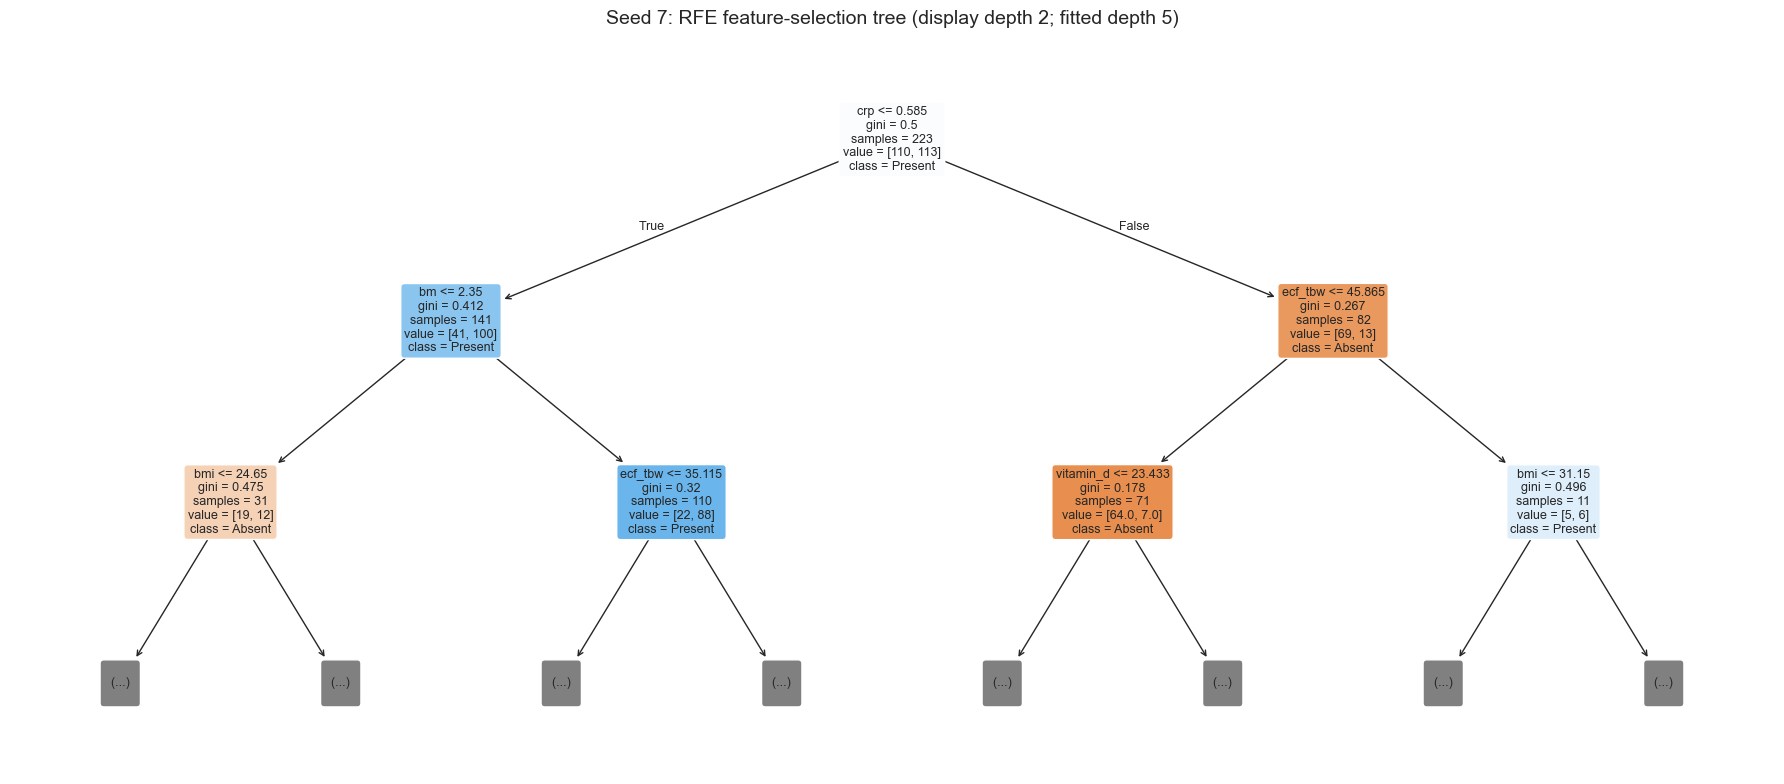

,seed,selector,input_features,fitted_depth,leaves,training_rows
0,42,cart,38,5,17,223
1,42,rfe,20,5,17,223
2,7,cart,38,5,17,223
3,7,rfe,20,5,17,223


Saved CART tree PNGs, PDFs and complete text rules to /Users/quyduong106/projects/INFOSYS722/Iteration3_OpenStack/transformed_dataset/visualizations


In [6]:
from sklearn.tree import plot_tree, export_text

TREE_SEEDS = SEEDS[:2]
TREE_DISPLAY_DEPTH = 2
TREE_SELECTORS = ["cart", "rfe"]
tree_details = []
for tree_seed in TREE_SEEDS:
    for tree_selection in TREE_SELECTORS:
        tree_directory = DATASET_DIR / "holdout" / f"seed_{tree_seed}" / tree_selection / "training"
        tree_preparation = load_pickle(tree_directory / "transformer.pkl")
        tree_selector = tree_preparation.named_steps["select"]
        fitted_tree = tree_selector.estimator_
        tree_features = tree_preparation.named_steps["impute"].get_feature_names_out()
        if tree_selection == "rfe":
            tree_features = tree_features[tree_selector.get_support()]
        assert len(tree_features) == fitted_tree.n_features_in_
        tree_class_names = [{0: "Absent", 1: "Present"}[int(label)] for label in fitted_tree.classes_]
        fig, ax = plt.subplots(figsize=(18, 8))
        plot_tree(fitted_tree, feature_names=list(tree_features), class_names=tree_class_names,
                  max_depth=TREE_DISPLAY_DEPTH, filled=True, rounded=True,
                  impurity=True, proportion=False, precision=3, fontsize=9, ax=ax)
        ax.set_title(f"Seed {tree_seed}: {tree_selection.upper()} feature-selection tree"
                     f" (display depth {TREE_DISPLAY_DEPTH}; fitted depth {fitted_tree.get_depth()})",
                     fontsize=14, pad=18)
        fig.tight_layout()
        stem = VIS_OUTPUT / f"cart_tree_seed_{tree_seed}_{tree_selection}"
        fig.savefig(stem.with_suffix(".png"), dpi=180, bbox_inches="tight")
        fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
        plt.show()
        stem.with_suffix(".txt").write_text(
            "Class mapping: 0 = gallstones absent, 1 = gallstones present.\n"
            + export_text(fitted_tree, feature_names=list(tree_features),
                          max_depth=fitted_tree.get_depth(), decimals=3))
        tree_details.append({"seed": tree_seed, "selector": tree_selection,
                             "input_features": fitted_tree.n_features_in_,
                             "fitted_depth": fitted_tree.get_depth(),
                             "leaves": fitted_tree.get_n_leaves(),
                             "training_rows": int(fitted_tree.tree_.n_node_samples[0])})
display(pd.DataFrame(tree_details))
print(f"Saved CART tree PNGs, PDFs and complete text rules to {VIS_OUTPUT}")
